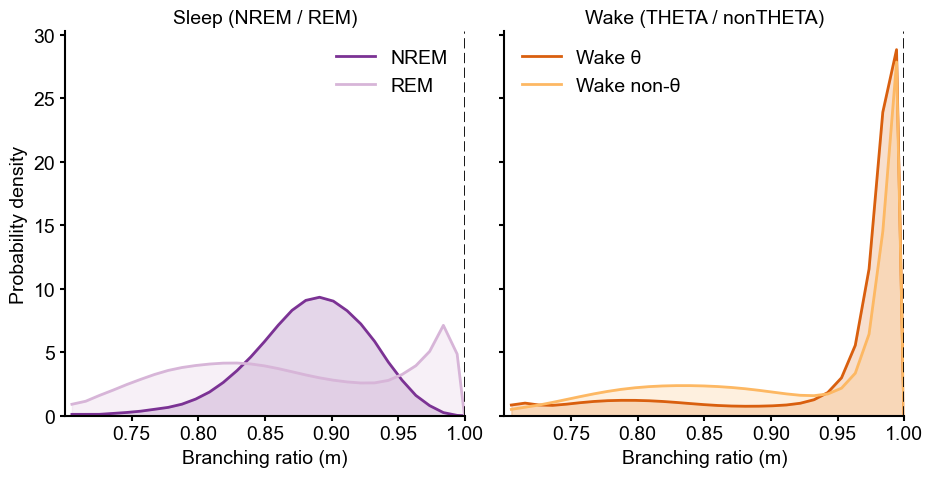

In [2]:
import os, glob, pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import nelpy as nel
import nelpy.plotting as npl
import numpy as np
import seaborn as sns
from neuro_py.io import loading
from neuro_py.plotting.figure_helpers import set_size
from neuro_py.tuning import maps
import os, re, glob
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
OUTDIR = r"D:\Documents\GitHub\Sleep_criticaltiy\data\cross_state\branching_ratio_1"
STATES = ["NREM", "REM", "THETA", "nonTHETA"]
SAVE_PREFIX = "pooled_branching_ratio_hist"

def _durations_from_centers(centers, fallback_step=None):
    c = np.asarray(centers, float)
    c = c[np.isfinite(c)]
    if c.size == 0:
        return c, np.array([])
    if fallback_step is not None and np.isfinite(fallback_step) and fallback_step > 0:
        return c, np.full_like(c, float(fallback_step), dtype=float)
    c = np.unique(np.sort(c))
    if c.size == 1:
        return c, np.array([fallback_step if fallback_step else 0.0])
    d = np.zeros_like(c, dtype=float)
    d[1:-1] = 0.5*(c[2:] - c[:-2]); d[0] = c[1]-c[0]; d[-1] = c[-1]-c[-2]
    return c, np.clip(d, 0.0, None)

def _get_branching_series(state_dict):
    if state_dict is None:
        return np.array([])
    for key in ("branching_ratios", "sigma", "m", "br"):
        if key in state_dict:
            v = np.asarray(state_dict[key], float)
            return v[np.isfinite(v)]
    return np.array([])
from pathlib import Path

ROOT = Path(r"W:\data\PPP")

def _build_basepath_from_meta(meta):
    animal = str(meta.get("animal", "")).strip()
    day    = str(meta.get("day", "")).strip()
    # day is expected in the form 'day8'
    basepath = ROOT / animal / day
    return basepath

def centers_in_intervals_bool(centers, intervals):
    """
    centers : 1D array
    intervals : (N,2) [start, stop)
    Returns boolean mask: True if center is in any interval.
    """
    centers = np.asarray(centers, float)
    if centers.size == 0 or intervals.size == 0:
        return np.zeros_like(centers, dtype=bool)

    starts = np.asarray(intervals[:,0], float)
    stops  = np.asarray(intervals[:,1], float)

    order = np.argsort(starts)
    starts = starts[order]
    stops  = stops[order]

    idx = np.searchsorted(starts, centers, side="right") - 1
    ok = (idx >= 0) & (centers < stops[np.clip(idx, 0, len(stops)-1)])
    return ok

def _get_sleep_intervals(basepath):
    """
    Load epoch_df and return intervals where environment == 'sleep'.
    Returns array shape (N,2) [start, stop).
    """
    try:
        epoch_df = loading.load_epoch(str(basepath))
    except Exception as e:
        print(f"⚠️ failed to load epoch for {basepath}: {e}")
        return np.empty((0, 2), float)

    if epoch_df is None or epoch_df.empty:
        return np.empty((0, 2), float)

    env = epoch_df.get("environment",
                       pd.Series([""] * len(epoch_df), index=epoch_df.index)
                      ).astype(str).str.lower()

    sleep_rows = env.eq("sleep")
    if not sleep_rows.any():
        return np.empty((0, 2), float)

    starts = pd.to_numeric(epoch_df.loc[sleep_rows, "startTime"], errors="coerce").to_numpy(float)
    stops  = pd.to_numeric(epoch_df.loc[sleep_rows, "stopTime"],  errors="coerce").to_numpy(float)

    mask = np.isfinite(starts) & np.isfinite(stops) & (stops > starts)
    intervals = np.column_stack([starts[mask], stops[mask]])
    return intervals

# ---------- LOAD & POOL ----------
pkl_paths = sorted(glob.glob(os.path.join(OUTDIR, "branching_ratio_allstates_*.pkl")))
if not pkl_paths:
    raise FileNotFoundError(f"No combined PKLs found in {OUTDIR}")

pooled_vals = {s: [] for s in STATES}
pooled_wts  = {s: [] for s in STATES}

pooled_vals = {st: [] for st in STATES}
pooled_wts  = {st: [] for st in STATES}

for pkl in pkl_paths:
    with open(pkl, "rb") as f:
        payload = pickle.load(f)

    meta = payload.get("meta", {})
    step = float(meta.get("step_size", np.nan))

    # --- build basepath and get sleep epochs ---
    basepath = _build_basepath_from_meta(meta)
    sleep_intervals = _get_sleep_intervals(basepath)  # (N,2) array, env == 'sleep'

    for st in STATES:
        if st not in payload:
            continue

        sd = payload[st]
        br = _get_branching_series(sd)
        if br.size == 0:
            continue

        centers = np.asarray(sd.get("centers", []), float)
        centers = centers[np.isfinite(centers)]
        n = min(br.size, centers.size)
        if n == 0:
            continue

        br = br[:n]
        centers = centers[:n]

        _, wts = _durations_from_centers(
            centers,
            fallback_step=step if np.isfinite(step) else None
        )
        wts = wts[:n]

        # base validity mask
        mask = np.isfinite(br) & np.isfinite(wts) & (wts > 0)

        # --- For THETA / nonTHETA, drop samples in sleep epochs ---
        if st in ("THETA", "nonTHETA") and sleep_intervals.size > 0:
            in_sleep = centers_in_intervals_bool(centers, sleep_intervals)
            mask &= ~in_sleep   # keep only centers NOT in sleep environment

        if not mask.any():
            continue

        pooled_vals[st].append(br[mask])
        pooled_wts[st].append(wts[mask])


# Concatenate pools
for st in STATES:
    pooled_vals[st] = np.concatenate(pooled_vals[st]) if pooled_vals[st] else np.array([])
    pooled_wts[st]  = np.concatenate(pooled_wts[st])  if pooled_wts[st]  else np.array([])

# ---------- BUILD BINS FROM TRUE RANGE + FORCE EDGE AT 1.0 ----------
finite_all = np.concatenate([pooled_vals[s] for s in STATES if pooled_vals[s].size > 0])
if finite_all.size == 0:
    raise RuntimeError("No finite branching-ratio values found.")

vmin = float(np.min(finite_all))
vmax = float(np.max(finite_all))
if not np.isfinite(vmin) or not np.isfinite(vmax) or vmin == vmax:
    vmin, vmax = 0.0, 1.2  # fallback

n_bins = 30  # total number of bins
# make base edges, then insert 1.0 exactly if it's inside range but not present
edges = np.linspace(vmin, vmax, n_bins + 1)
if (vmin < 1.0 < vmax) and not np.any(np.isclose(edges, 1.0)):
    edges = np.sort(np.unique(np.r_[edges, 1.0]))  # add 1.0 as a bin edge

BR_BINS = edges  # use these for all states

# ---------- HISTOGRAMS (fraction of time) + REPORT m>1 ----------
# ---------- ROBUST BIN RANGE + FORCE EDGE AT 1.0 ----------
finite_all = np.concatenate([pooled_vals[s] for s in STATES if pooled_vals[s].size > 0])
if finite_all.size == 0:
    raise RuntimeError("No finite branching-ratio values found.")

p_lo, p_hi = 1.0, 99.0
low, high = np.percentile(finite_all, [p_lo, p_hi])
span = max(high - low, 1e-6)
margin = 0.05 * span
robust_min = low  - margin
robust_max = high + margin

n_bins = 30
edges = np.linspace(robust_min, robust_max, n_bins + 1)

# insert exact 1.0 if inside range and not present
if (robust_min < 1.0 < robust_max) and not np.any(np.isclose(edges, 1.0)):
    edges = np.sort(np.unique(np.r_[edges, 1.0]))

# bins for plotting (centers correspond to ALL finite bins)
bin_centers = 0.5 * (edges[:-1] + edges[1:])

# overflow-aware edges for counting tails:
# (-inf, edges[1]), (edges[1], edges[2]), ..., (edges[-2], +inf)
hist_edges = np.r_[-np.inf, edges[1:-1], np.inf]
import numpy as np
from scipy.stats import gaussian_kde
import matplotlib as mpl

import matplotlib as mpl

# Global font: prefer Arial, with safe fallbacks
mpl.rcParams['svg.fonttype'] = 'none' 
mpl.rcParams['text.usetex'] = False
mpl.rcParams['font.family'] = 'sans-serif'
mpl.rcParams['font.family'] = 'sans-serif'
mpl.rcParams['font.sans-serif'] = [
    'Helvetica Neue', 'Helvetica', 'Arial', 'Liberation Sans', 'DejaVu Sans'
]

# Mathtext to match
mpl.rcParams['mathtext.fontset'] = 'custom'
mpl.rcParams['mathtext.rm'] = 'Helvetica Neue'   # or 'Helvetica'
mpl.rcParams['mathtext.it'] = 'Helvetica Neue:italic'
mpl.rcParams['mathtext.bf'] = 'Helvetica Neue:bold'

# (optional) sizes + minus sign
mpl.rcParams['font.size'] = 16
mpl.rcParams['axes.titlesize'] = 14
mpl.rcParams['axes.labelsize'] = 14
mpl.rcParams['xtick.labelsize'] = 14
mpl.rcParams['ytick.labelsize'] = 14
mpl.rcParams['legend.fontsize'] = 14
mpl.rcParams['axes.unicode_minus'] = False

# Global sizes (tweak to taste)
mpl.rcParams['font.size'] = 14
mpl.rcParams['axes.titlesize'] = 14
mpl.rcParams['axes.labelsize'] = 14
mpl.rcParams['xtick.labelsize'] = 14
mpl.rcParams['ytick.labelsize'] = 14
mpl.rcParams['legend.fontsize'] = 14
mpl.rcParams["axes.linewidth"] = 1.5       # spine width
mpl.rcParams["xtick.major.width"] =1.5
mpl.rcParams["ytick.major.width"] = 1.5
mpl.rcParams["xtick.minor.width"] = 1.5
mpl.rcParams["ytick.minor.width"] = 1.5
mpl.rcParams["axes.linewidth"] = 1.5       # spine width
mpl.rcParams["xtick.major.width"] =1.5
mpl.rcParams["ytick.major.width"] = 1.5
mpl.rcParams["xtick.minor.width"] = 1.5
mpl.rcParams["ytick.minor.width"] = 1.5
# --- Step 1: Load all files ---
hist_rows = []
above1_summary = {}
tails_summary  = {}
LEGEND_LABELS = ["NREM", "REM", "Wake θ", "Wake non-θ"]
colors = {
    "NREM": "#7b3294",
    "REM": "#d7b5d8",
    "THETA": "#d95f0e",
    "nonTHETA": "#fdb863"
}

def kde_pdf_logit(m, w, edges, low, high=1.0, bw=0.25):
    m = np.asarray(m, float); w = np.asarray(w, float)
    ok = np.isfinite(m) & np.isfinite(w) & (w > 0) & (m > low) & (m < high)
    m, w = m[ok], w[ok]
    if m.size == 0:
        return np.zeros(len(edges)-1)

    eps = 1e-6
    p = (m - low) / (high - low)
    p = np.clip(p, eps, 1 - eps)

    t = np.log(p) - np.log1p(-p)

    kde = gaussian_kde(t, weights=w, bw_method=bw)

    centers = 0.5 * (edges[:-1] + edges[1:])
    pg  = np.clip((centers - low) / (high - low), eps, 1 - eps)
    tg  = np.log(pg) - np.log1p(-pg)

    ft = kde(tg)

    jac = 1.0 / ((high - low) * pg * (1 - pg))

    # THIS is the probability density at bin centers
    fm = ft * jac

    # normalize density so ∫fm dm = 1
    widths = np.diff(edges)
    Z = np.sum(fm * widths)
    if Z > 0:
        fm = fm / Z

    return fm


# --- plotting example ---
low, high = float(edges[0]), 1.0

fig, axes = plt.subplots(1, 2, figsize=(9.5, 5), sharey=True)
ax_sleep, ax_wake = axes

# --- PANEL 1: Sleep (NREM + REM) ---
for st, label in zip(STATES, LEGEND_LABELS):
    if st not in ["NREM", "REM"]:
        continue  # only sleep states here
    x, w = pooled_vals[st], pooled_wts[st]
    pdf = kde_pdf_logit(x, w, edges, low, high, bw=0.20)
    ax_sleep.plot(bin_centers, pdf, lw=2, label=label, color=colors[st])
    ax_sleep.fill_between(bin_centers, pdf, alpha=0.2, color=colors[st])

ax_sleep.axvline(1.0, ls="--", lw=2, color="k")
ax_sleep.set_xlim(low, high)
ax_sleep.set_xlabel("Branching ratio (m)")
ax_sleep.set_ylabel("Probability density")
ax_sleep.set_title("Sleep (NREM / REM)")
ax_sleep.legend(frameon=False)
ax_sleep.spines["top"].set_visible(False)
ax_sleep.spines["right"].set_visible(False)

# --- PANEL 2: Wake (THETA + nonTHETA) ---
for st, label in zip(STATES, LEGEND_LABELS):
    if st not in ["THETA", "nonTHETA"]:
        continue  # only wake states here
    x, w = pooled_vals[st], pooled_wts[st]
    pdf = kde_pdf_logit(x, w, edges, low, high, bw=0.20)
    ax_wake.plot(bin_centers, pdf, lw=2, label=label, color=colors[st])
    ax_wake.fill_between(bin_centers, pdf, alpha=0.2, color=colors[st])

ax_wake.axvline(1.0, ls="--", lw=2, color="k")
ax_wake.set_xlim(low, high)
ax_wake.set_ylim(bottom=0)
ax_wake.set_xlabel("Branching ratio (m)")
ax_wake.set_title("Wake (THETA / nonTHETA)")
ax_wake.legend(frameon=False)
ax_wake.spines["top"].set_visible(False)
ax_wake.spines["right"].set_visible(False)

plt.tight_layout()
save_path = r"D:\Documents\GitHub\Sleep_criticaltiy\reports\new_planc\supplementary\individual_fig_supp\S1_F_branching_ratio_distribution_split.svg"
plt.savefig(save_path, dpi=300)
plt.show()